Ian Pope (700717419)  
CNN & RNN Project

Task A - CNN Image Classification with CIFAR-10

In [ ]:
#Load necessary libraries
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
#1 Load CIFAR-10 and report metrics
(x_train, y_train), (x_test, y_test) = (tf.keras.datasets.cifar10.load_data())

print("Training samples:", x_train.shape[0])
print("Testing samples:", x_test.shape[0])

print("Training image dimensions:", x_train.shape[1:])
print("Testing image dimensions:", x_test.shape[1:])

print("Number of classes:", len(np.unique(y_train)))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step
Training samples: 50000
Testing samples: 10000
Training image dimensions: (32, 32, 3)
Testing image dimensions: (32, 32, 3)
Number of classes: 10


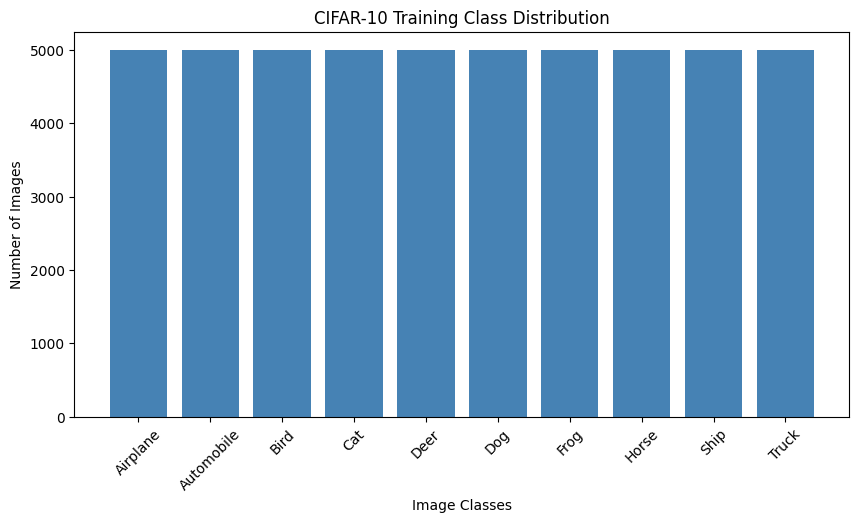

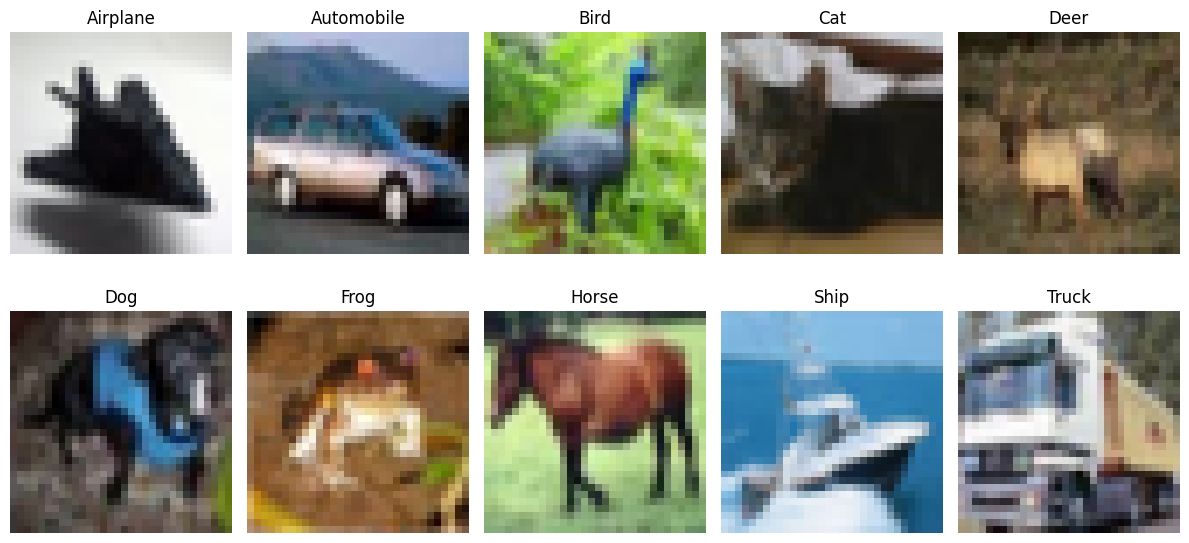

In [ ]:
#2 Get the class distribution and print representative pictures
class_names = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
               'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

class_counts = np.bincount(y_train.flatten(), minlength=10)

plt.figure(figsize=(10, 5))

plt.bar(class_names, class_counts, color='steelblue')

plt.title("CIFAR-10 Training Class Distribution")
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)

plt.show()

plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    index = np.where(y_train.flatten() == i)[0][0]

    plt.imshow(x_train[index])
    plt.title(class_names[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
#3 Preprocess and normalize data

#Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

#Convert labels to one-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, 10)
y_test = tf.keras.utils.to_categorical(y_test, 10)

print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

Training data shape: (50000, 32, 32, 3)
Training labels shape: (50000, 10)


In [ ]:
#4 Build the CNN

model = models.Sequential([

    #Add convolutional and pooling layers
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    #Add another convolutional and pooling layer
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    #Add classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),

    #Final output layer
    layers.Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#5a Compile the model

#Model settings
learning_rate = 0.001
batch_size = 64
epochs = 20
loss_fn = 'categorical_crossentropy'
optimizer = 'Adam'

#Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss=loss_fn,
              metrics=['accuracy'])

In [ ]:
#5b Train the model
history = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                    validation_split=0.2, verbose=1)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 14s 11ms/step - accuracy: 0.3968 - loss: 1.6551 - val_accuracy: 0.5380 - val_loss: 1.3152
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5304 - loss: 1.3089 - val_accuracy: 0.6058 - val_loss: 1.1374
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5854 - loss: 1.1635 - val_accuracy: 0.6371 - val_loss: 1.0426
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6176 - loss: 1.0679 - val_accuracy: 0.6485 - val_loss: 1.0002
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6484 - loss: 1.0013 - val_accuracy: 0.6713 - val_loss: 0.9336
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.6651 - loss: 0.9467 - val_accuracy: 0.6692 - val_loss: 0.9515
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6800 - loss: 0.8999 - val_accuracy: 0.6714 - val_loss: 0.9290
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6966 - loss: 0.8546 - val_accuracy: 

In [ ]:
#6a Evaluate on the test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

y_pred = model.predict(x_test)

y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6901 - loss: 1.0112
Test Loss: 1.0111663341522217
Test Accuracy: 0.6901000142097473
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    Airplane       0.68      0.80      0.74      1000
  Automobile       0.81      0.77      0.79      1000
        Bird       0.67      0.53      0.59      1000
         Cat       0.55      0.45      0.49      1000
        Deer       0.61      0.68      0.64      1000
         Dog       0.59      0.60      0.59      1000
        Frog       0.73      0.76      0.75      1000
       Horse       0.69      0.78      0.73      1000
        Ship       0.87      0.72      0.79      1000
       Truck       0.72      0.81      0.76      1000

    accuracy                           0.69     10000
   macro avg       0.69      0.69      0.69     10000
weighted avg       0.69      0.69      0.69     10000



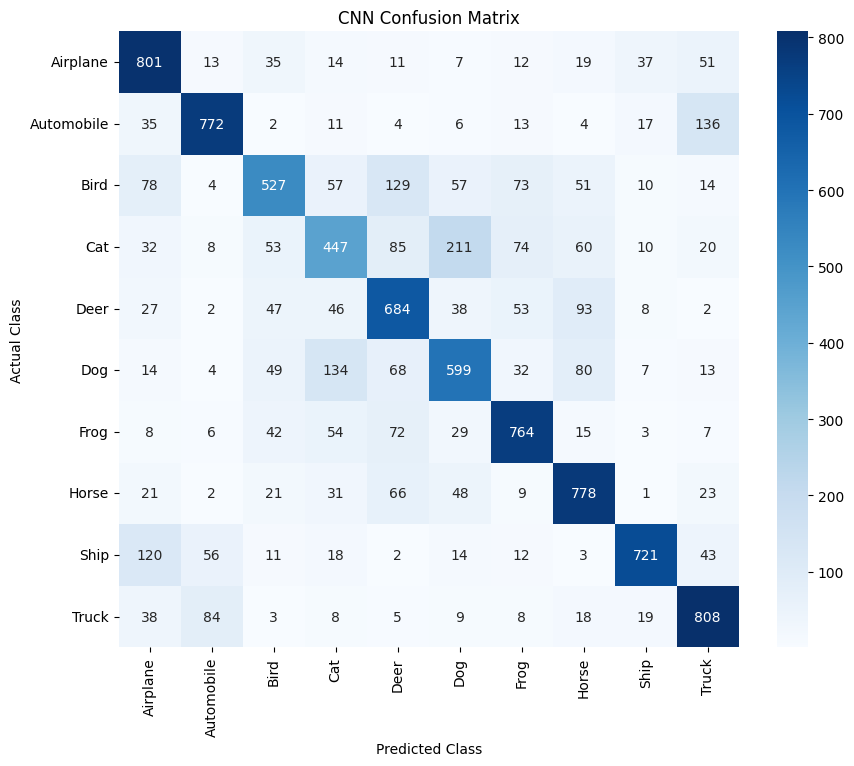

In [ ]:
#6b Create a confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

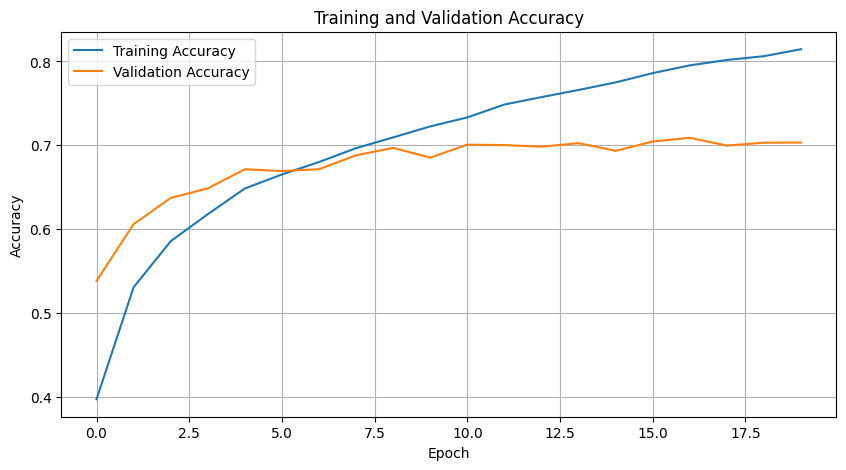

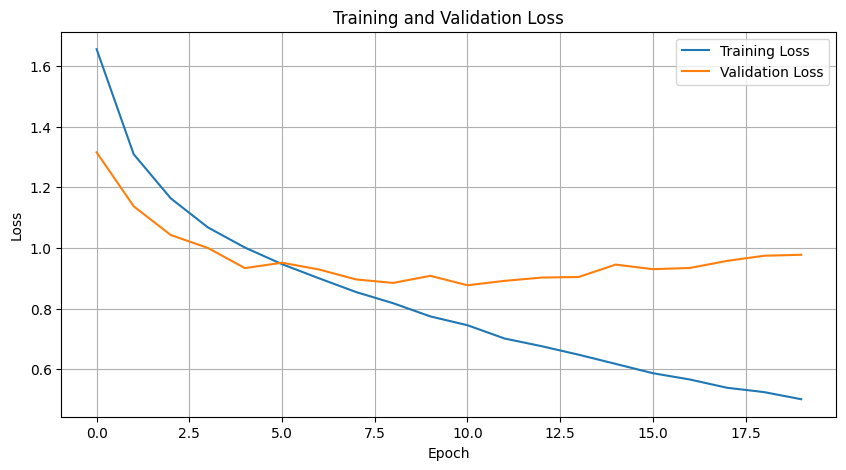

In [ ]:
#7 Plot training and validation accuracy & loss

#Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'],label='Validation Accuracy')

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

#Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'],label='Validation Loss')

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

\#7b Over/Underfitting

In [ ]:
#8a CNN Experiment
#I am adding in a dropout layer of 0.5 to the exact same model

#4 Build the CNN

model = models.Sequential([

    #Add convolutional and pooling layers
    layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(32, 32, 3)),
    layers.MaxPooling2D((2, 2)),

    #Add another convolutional and pooling layer
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    #Add classification layers
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),

    #Final output layer
    layers.Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,098 (2.08 MB)

 Trainable params: 545,098 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#8b Compile the new model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
              loss=loss_fn,
              metrics=['accuracy'])

In [ ]:
#8c Train the new model
history = model.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
                    validation_split=0.2, verbose=1)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step - accuracy: 0.3752 - loss: 1.7081 - val_accuracy: 0.5085 - val_loss: 1.3833
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5062 - loss: 1.3715 - val_accuracy: 0.5963 - val_loss: 1.1484
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5611 - loss: 1.2264 - val_accuracy: 0.6178 - val_loss: 1.0977
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.5975 - loss: 1.1326 - val_accuracy: 0.6363 - val_loss: 1.0288
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6238 - loss: 1.0601 - val_accuracy: 0.6698 - val_loss: 0.9375
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6454 - loss: 1.0060 - val_accuracy: 0.6769 - val_loss: 0.9218
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6637 - loss: 0.9601 - val_accuracy: 0.6948 - val_loss: 0.8881
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6757 - loss: 0.9159 - val_accuracy: 0.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7138 - loss: 0.8980
Test Loss: 0.8979607224464417
Test Accuracy: 0.7138000130653381
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
              precision    recall  f1-score   support

    Airplane       0.71      0.77      0.74      1000
  Automobile       0.88      0.78      0.83      1000
        Bird       0.59      0.63      0.61      1000
         Cat       0.53      0.49      0.51      1000
        Deer       0.66      0.69      0.67      1000
         Dog       0.63      0.61      0.62      1000
        Frog       0.80      0.78      0.79      1000
       Horse       0.76      0.78      0.77      1000
        Ship       0.84      0.79      0.82      1000
       Truck       0.76      0.83      0.80      1000

    accuracy                           0.71     10000
   macro avg       0.72      0.71      0.71     10000
weighted avg       0.72      0.71      0.71     10000



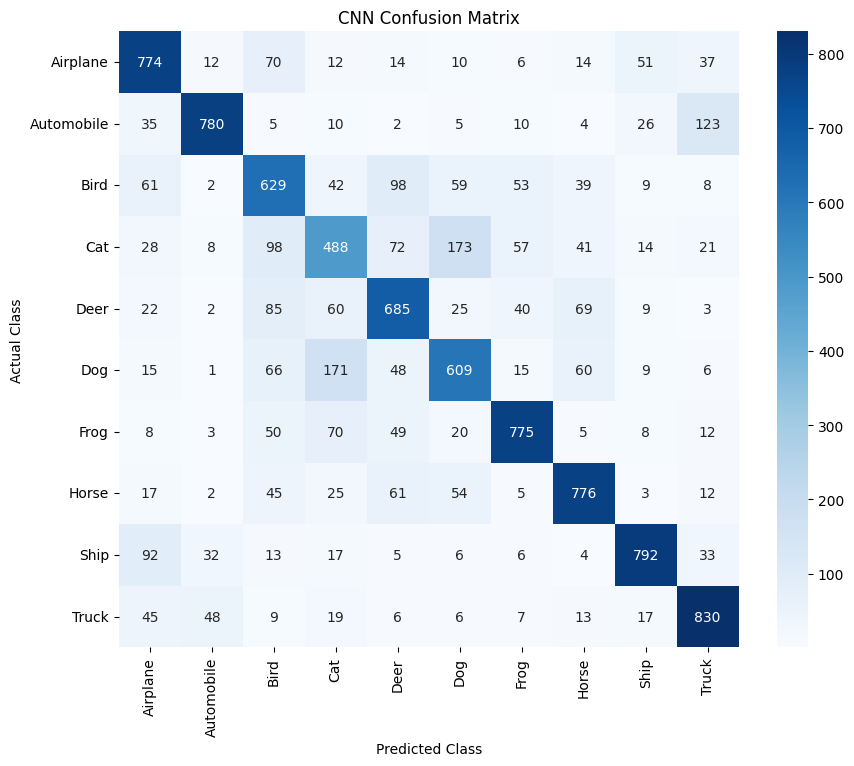

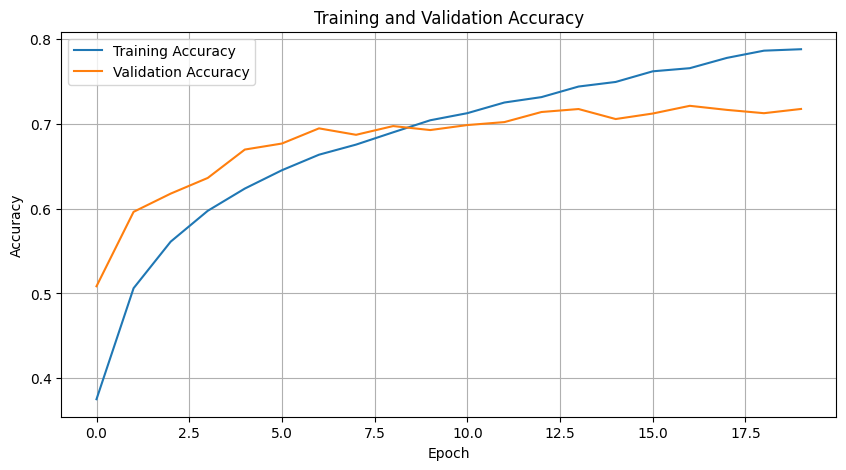

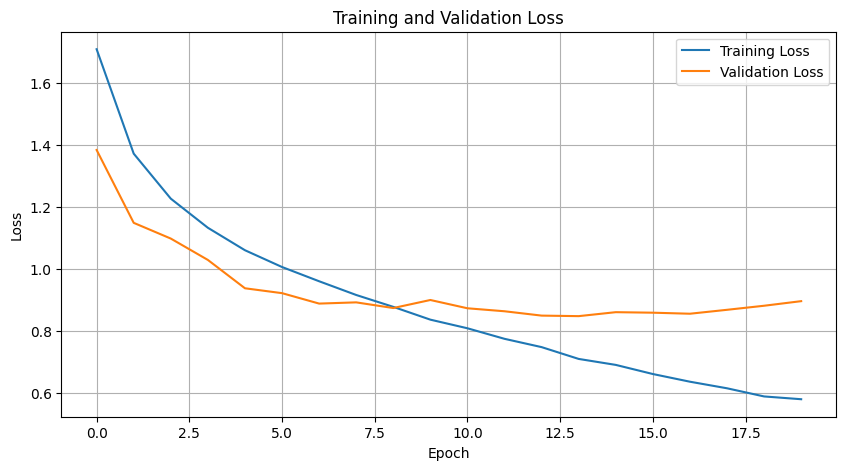

In [ ]:
#8d Perform new model analysis

#Evaluate mertics on test data
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_acc)

y_pred = model.predict(x_test)

y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

print(classification_report(y_true_classes, y_pred_classes, target_names=class_names))

#Create a confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.show()

#Plot training and validation accuracy
plt.figure(figsize=(10, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')

plt.plot(history.history['val_accuracy'],label='Validation Accuracy')

plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

#Plot training and validation loss
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')

plt.plot(history.history['val_loss'],label='Validation Loss')

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

\#9 Results of the experiment  
The second model that utilized an additional doprout layer with a dropout rate of 0.5 performed better on the test data. The likely reason that this performmed better is that the model with dropout was able to generalize better and prevent overfitting of the model.

CNN Analysis Questions  


*   Early level convolutional layers learn simple
patterns such as edges, corners, or points. With deeper layers they are also able to spot different patters including full parts, shapes, and textures.  
*   The purpose of pooling in this model is to generalize the layers inputs and reduce the number of dimensions.
*   The most commonly confused images were predicted dog instead of cat, cat instead of dog, and automobile instead of truck. None of these are surprising as each of the predicted values share many similar traits to the actual values.
*   The addition of the dropout layer marginally helped in reducing overfitting as well as improving the models generalization.

Task B - RNN Sequence Classification

In [ ]:
#Load in required libraries
#Libraries from beginning of the file are also required if using a new runtime
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
#10 Load dataset and get information about it

#Limit the number of most frequent words to pull
vocab_size = 10000
(x_train, y_train), (x_test, y_test) = imdb.load_data(num_words=vocab_size)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

print("Number of classes:", len(np.unique(y_train)))

print("Training labels:", np.unique(y_train))

print("Negative: 0; Positive: 1")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Testing samples: 25000
Number of classes: 2
Training labels: [0 1]
Negative: 0; Positive: 1


Shortest review: 11
Longest review: 2494
Average review length: 238.71364
Median review length: 178.0


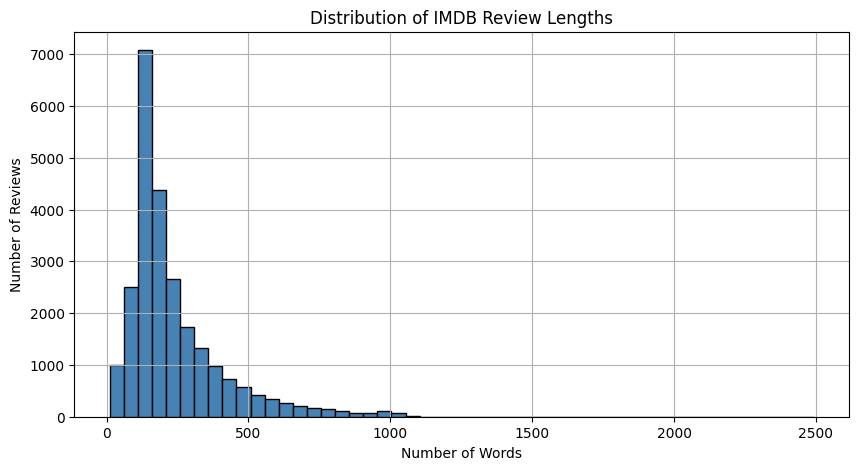

Negative reviews: 12500
Positive reviews: 12500


In [ ]:
#11a Examine Sequence length and label distributions

#Get all lengths
review_lengths = [len(review) for review in x_train]

print("Shortest review:", min(review_lengths))
print("Longest review:", max(review_lengths))
print("Average review length:", np.mean(review_lengths))
print("Median review length:", np.median(review_lengths))

#Plot the length distribution
plt.figure(figsize=(10, 5))

plt.hist(review_lengths, bins=50, color='steelblue', edgecolor='black')

plt.title("Distribution of IMDB Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")

plt.grid(True)
plt.show()

#Get y label counts
unique, counts = np.unique(y_train, return_counts=True)

print("Negative reviews:", counts[0])
print("Positive reviews:", counts[1])

\#11b Explain how words are converted to integer sequences or embeddings  
In the case of this dataset, the words are already embedded as an integer when they are pulled. In general, one strategy is to take the x number of the most common words in the dataset and encode them as integers. Other strategies may use trained encoder to create vectors that correspond to words.

In [ ]:
#12 Prepare sequences for training

#The data for this dataset is already tokenized when pulled in

#Trim and pad sequences
max_length = 200
x_train_padded = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)
x_test_padded = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

In [ ]:
#13 Build an LSTM model

model = models.Sequential([

    #Convert integer sequences into word vectors
    layers.Embedding(input_dim=10000, output_dim=128, input_length=200),

    #LSTM layer
    layers.LSTM(64),

    #Dropout
    layers.Dropout(0.3),

    #Classification layer
    layers.Dense(1, activation='sigmoid')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#14a Compile the model
learning_rate = 0.001
loss_fn = 'binary_crossentropy'
optimizer = 'Adam'
epochs = 10
batch_size = 64

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss=loss_fn,
    metrics=['accuracy']
)

In [ ]:
#14b Train the model
history = model.fit(
    x_train_padded,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.5335 - loss: 0.6872 - val_accuracy: 0.5300 - val_loss: 0.6918
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.5657 - loss: 0.6713 - val_accuracy: 0.5766 - val_loss: 0.6596
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.6245 - loss: 0.5991 - val_accuracy: 0.6048 - val_loss: 0.6327
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7404 - loss: 0.5026 - val_accuracy: 0.7926 - val_loss: 0.5034
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8789 - loss: 0.3256 - val_accuracy: 0.8338 - val_loss: 0.3902
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9173 - loss: 0.2324 - val_accuracy: 0.8556 - val_loss: 0.3906
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9440 - loss: 0.1744 - val_accuracy: 0.8548 - val_loss: 0.4282
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9603 - loss: 0.1280 - val_acc

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8275 - loss: 0.6163
Test Loss: 0.6163075566291809
Test Accuracy: 0.8274800181388855
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
              precision    recall  f1-score   support

    Negative       0.82      0.84      0.83     12500
    Positive       0.84      0.82      0.83     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



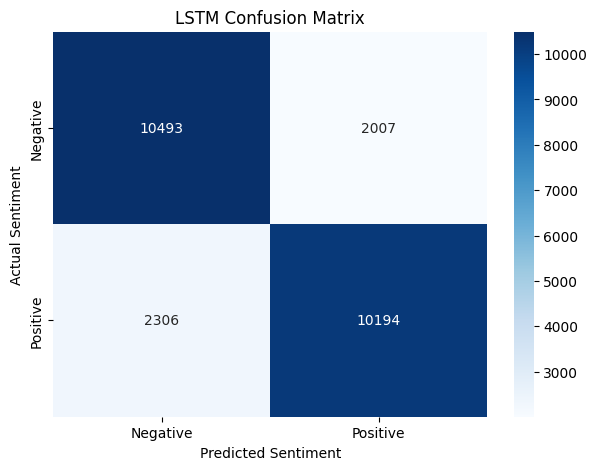

In [ ]:
#15 Evaluate the model on test data
test_loss, test_accuracy = model.evaluate(x_test_padded, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

#Get test predictions
y_pred = model.predict(x_test_padded)
y_pred_classes = (y_pred >= 0.5).astype(int).flatten()

#Get all statistics on the predictions
print(classification_report(y_test, y_pred_classes, target_names=['Negative', 'Positive']))

#Get and plot a confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

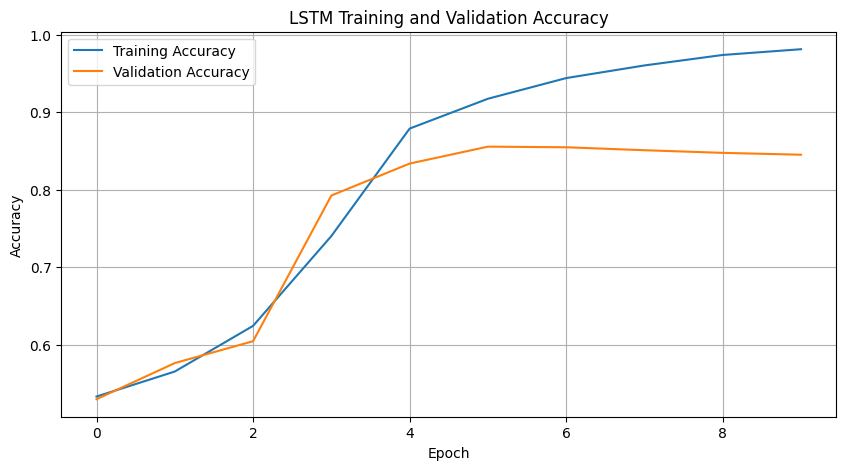

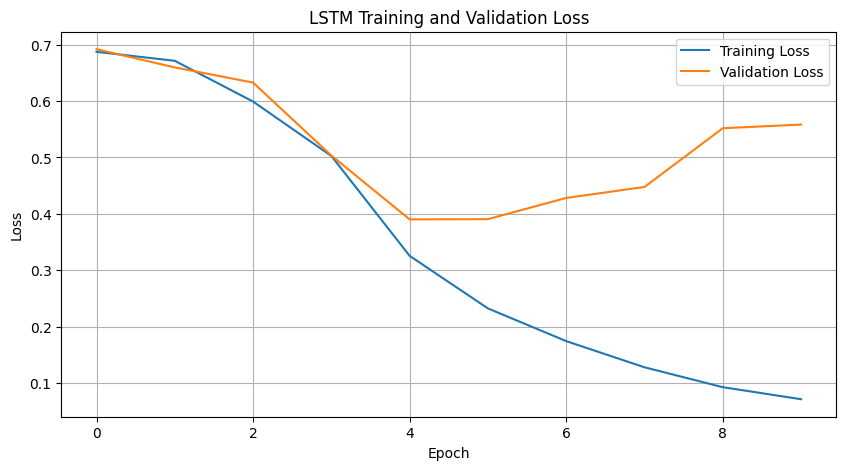

In [ ]:
#16a Plot training/validation accuracy and loss

#Plot accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()


#Plot loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

\#16b Discuss model learning behavior  
In the model training graphs we can visually see a pretty sharp climb in accuracy through the first few epochs. However around epoch 4 and 5, we can observe that validation accuracy and loss stagnate despite the training accuracy and loss improving. After that, validation loss and accuracy start to get worse as the model becomes overfitted to the training dataset.

In [ ]:
#17a Conduct an experiment on the model
# This model will increase the input sequence length to 250

#Trim and pad sequences
max_length = 250
x_train_padded = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)
x_test_padded = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

model = models.Sequential([

    #Convert integer sequences into word vectors
    layers.Embedding(input_dim=10000, output_dim=128, input_length=250),

    #LSTM layer
    layers.LSTM(64),

    #Dropout
    layers.Dropout(0.3),

    #Classification layer
    layers.Dense(1, activation='sigmoid')
])

model.summary()



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#17b Compile and train model
learning_rate = 0.001
loss_fn = 'binary_crossentropy'
optimizer = 'Adam'
epochs = 10
batch_size = 64

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
    loss=loss_fn,
    metrics=['accuracy']
)

history = model.fit(
    x_train_padded,
    y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.2,
    verbose=1
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - accuracy: 0.5088 - loss: 0.6931 - val_accuracy: 0.5240 - val_loss: 0.6911
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.5602 - loss: 0.6738 - val_accuracy: 0.5700 - val_loss: 0.6860
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6299 - loss: 0.6322 - val_accuracy: 0.5704 - val_loss: 0.6594
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.6686 - loss: 0.5917 - val_accuracy: 0.7570 - val_loss: 0.5860
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6279 - loss: 0.6184 - val_accuracy: 0.5778 - val_loss: 0.6667
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6375 - loss: 0.5650 - val_accuracy: 0.5798 - val_loss: 0.6911
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.8248 - loss: 0.3849 - val_accuracy: 0.8400 - val_loss: 0.4054
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.9155 - loss: 0.2367 - val_acc

782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8317 - loss: 0.5647
Test Loss: 0.5647169351577759
Test Accuracy: 0.8317199945449829
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step
              precision    recall  f1-score   support

    Negative       0.80      0.88      0.84     12500
    Positive       0.87      0.79      0.82     12500

    accuracy                           0.83     25000
   macro avg       0.83      0.83      0.83     25000
weighted avg       0.83      0.83      0.83     25000



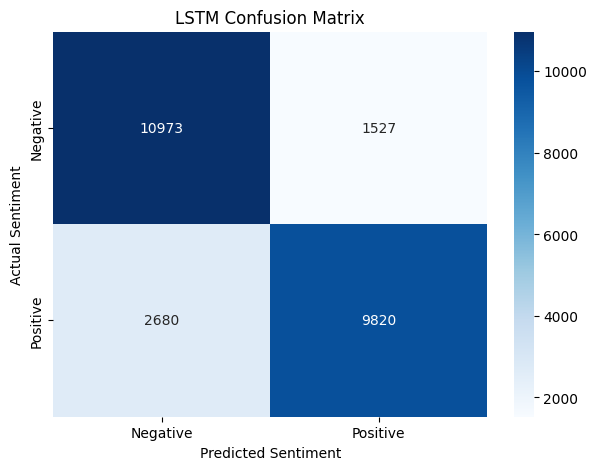

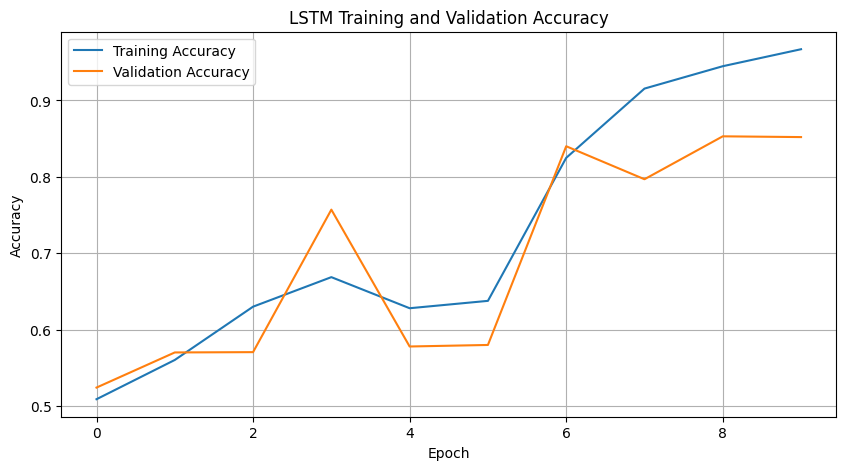

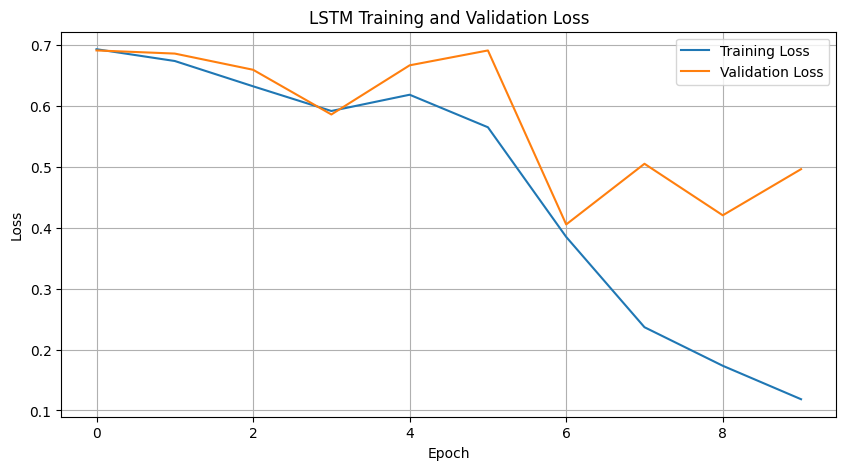

In [ ]:
#17c Evaluate the new model
test_loss, test_accuracy = model.evaluate(x_test_padded, y_test, verbose=1)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

#Get test predictions
y_pred = model.predict(x_test_padded)
y_pred_classes = (y_pred >= 0.5).astype(int).flatten()

#Get all statistics on the predictions
print(classification_report(y_test, y_pred_classes, target_names=['Negative', 'Positive']))

#Get and plot a confusion matrix
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

plt.title("LSTM Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()


#Plot accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()


#Plot loss
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

\#18 Compare variants and explain performance  
This experiment took the same model with one small change. The first model utilized the first 200 words of the text while the second used 250. The final accuracy and loss measurements between the models were very similar in performance with a very slight edge to the model with 250 words. This may show that one or both of these may be true that the model is abel to discerne between the groups just as well with less words or that the excess missing characters may hurt the models ability to evaluate the reviews.

RNN Analysis Questions
*   The ordering of the input sequences is important because the surrounding words may provide context to the individual input word
*   The information that is retained in the recurrent hidden state is the memory of information that is retained from previous time steps
*   Basic RNNs can stuggle with long term dependencies because the information from much earlier can get washed away over time (vanishing gradient).
*   LSTM and GRU units can better address the issue because they have gates in the unit to decide what information to store and what information to get rid of.
*   Based on the testing accuracy and loss between two identical LSTM networks with sequence lengths of 200 and 250 words, the evidence supports the 250 word sequence very slightly. The loss of the frist model was 0.616 vs 0.565 for the second model. In addition, the first model had an accuracy of 0.827 vs the second's 0.832. This is difference of just 0.005 in accuracy.